# 1. SPY option chains: download and clean
I download every SPY option expiry from Yahoo Finance (8 October 2026, 9,474 options) and clean them down to the ones good enough to compute implied volatility from.

In [1]:
import yfinance as yf
import pandas as pd
import time
import matplotlib.pyplot as plt

In [2]:
spy = yf.Ticker("SPY")
spot = spy.history(period="1d")["Close"].iloc[-1]
print("SPY spot price:", round(spot, 2))

SPY spot price: 772.65


In [3]:
expiries = spy.options
print("Number of expiry dates:", len(expiries))
print(expiries[:10])

Number of expiry dates: 29
('2026-10-08', '2026-10-09', '2026-10-12', '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16', '2026-10-23', '2026-10-30', '2026-11-06')


Before downloading everything, I look at one expiry to see what Yahoo gives back. Each row is one strike. The columns I actually use are strike, bid and ask (the mid-price is my estimate of the option's value). Volume and open interest are only for cleaning, and Yahoo's own impliedVolatility is kept just to compare with my numbers in notebook 2.

In [4]:
chain = spy.option_chain(expiries[9])
calls = chain.calls
puts = chain.puts
print("Expiry:", expiries[9])
print("Number of calls:", len(calls), " Number of puts:", len(puts))
calls.head()

Expiry: 2026-11-06
Number of calls: 124  Number of puts: 120


,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency
0,SPY261106C00640000,2026-10-02 13:47:47+00:00,640.0,134.54,133.28,136.01,0.000000,0.000000,2.0,0,0.462469,True,REGULAR,USD
1,SPY261106C00660000,2026-09-28 15:39:06+00:00,660.0,109.67,113.50,116.22,0.000000,0.000000,NaN,1,0.409186,True,REGULAR,USD
2,SPY261106C00675000,2026-09-29 17:10:29+00:00,675.0,92.52,98.64,101.44,0.000000,0.000000,NaN,3,0.370307,True,REGULAR,USD
3,SPY261106C00680000,2026-10-08 16:57:31+00:00,680.0,96.32,93.74,96.51,4.519997,4.923743,3.0,12,0.357001,True,REGULAR,USD
4,SPY261106C00685000,2026-09-30 14:09:32+00:00,685.0,87.16,88.81,91.62,0.000000,0.000000,1.0,5,0.344550,True,REGULAR,USD


Now the full download: calls and puts for every expiry in one table.

In [10]:
all_options = []
for expiry in expiries:
    chain = spy.option_chain(expiry)

    calls = chain.calls.copy()
    calls["type"] = "call"

    puts = chain.puts.copy()
    puts["type"] = "put"

    both = pd.concat([calls, puts])
    both["expiry"] = expiry

    all_options.append(both)
    time.sleep(0.3)  # short pause between requests so Yahoo doesn't block us

options = pd.concat(all_options, ignore_index=True)
print("Total options downloaded:", len(options))
options.head()

Total options downloaded: 9474


,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,type,expiry
0,SPY261008C00595000,2026-10-08 13:53:18+00:00,595.0,180.48,177.61,177.97,-1.75,-0.960325,8.0,6,2.039067,True,REGULAR,USD,call,2026-10-08
1,SPY261008C00615000,2026-10-07 18:28:15+00:00,615.0,162.59,157.65,157.99,0.00,0.000000,12.0,8,1.453128,True,REGULAR,USD,call,2026-10-08
2,SPY261008C00640000,2026-10-06 14:07:30+00:00,640.0,140.15,133.03,133.34,0.00,0.000000,2.0,0,1.701173,True,REGULAR,USD,call,2026-10-08
3,SPY261008C00645000,2026-10-07 15:57:24+00:00,645.0,132.26,127.65,127.98,0.00,0.000000,4.0,1,1.140629,True,REGULAR,USD,call,2026-10-08
4,SPY261008C00650000,2026-10-07 15:57:12+00:00,650.0,127.25,122.65,122.99,0.00,0.000000,8.0,7,1.125004,True,REGULAR,USD,call,2026-10-08


In [11]:
options.to_csv("spy_options_raw.csv", index=False)

In [12]:
options = options[["type", "expiry", "strike", "bid", "ask", "lastPrice", "volume", "openInterest", "impliedVolatility", "lastTradeDate"]].copy()
print(options.shape)
options.head(10)

(9474, 10)


,type,expiry,strike,bid,ask,lastPrice,volume,openInterest,impliedVolatility,lastTradeDate
0,call,2026-10-08,595.0,177.61,177.97,180.48,8.0,6,2.039067,2026-10-08 13:53:18+00:00
1,call,2026-10-08,615.0,157.65,157.99,162.59,12.0,8,1.453128,2026-10-07 18:28:15+00:00
2,call,2026-10-08,640.0,133.03,133.34,140.15,2.0,0,1.701173,2026-10-06 14:07:30+00:00
3,call,2026-10-08,645.0,127.65,127.98,132.26,4.0,1,1.140629,2026-10-07 15:57:24+00:00
4,call,2026-10-08,650.0,122.65,122.99,127.25,8.0,7,1.125004,2026-10-07 15:57:12+00:00
5,call,2026-10-08,655.0,117.83,118.18,122.25,6.0,3,1.390628,2026-10-07 15:57:03+00:00
6,call,2026-10-08,660.0,112.82,113.18,116.37,4.0,19,1.330081,2026-10-07 15:56:52+00:00
7,call,2026-10-08,665.0,107.90,108.34,111.34,5.0,7,1.359378,2026-10-07 15:56:41+00:00
8,call,2026-10-08,670.0,102.78,103.10,106.38,4.0,7,1.162114,2026-10-07 15:56:31+00:00
9,call,2026-10-08,675.0,97.90,98.34,100.52,2.0,5,1.242191,2026-10-07 14:05:33+00:00


Black-Scholes needs time to expiry T in years, the option price (I use the mid) and the spot. Moneyness K / S says how far each strike is from the current price.

In [29]:
today = pd.Timestamp.today().normalize()  # midnight, so T counts whole days
options["expiry"] = pd.to_datetime(options["expiry"])
options["T"] = (options["expiry"] - today).dt.days / 365
options["mid"] = (options["bid"] + options["ask"]) / 2
options["spot"] = spot
options["moneyness"] = options["strike"] / spot
options[["type", "expiry", "T", "strike", "moneyness", "bid", "ask", "mid"]].head(10)

,type,expiry,T,strike,moneyness,bid,ask,mid
0,call,2026-10-08,0.0,595.0,0.770077,177.61,177.97,177.790
1,call,2026-10-08,0.0,615.0,0.795962,157.65,157.99,157.820
2,call,2026-10-08,0.0,640.0,0.828318,133.03,133.34,133.185
3,call,2026-10-08,0.0,645.0,0.834789,127.65,127.98,127.815
4,call,2026-10-08,0.0,650.0,0.841261,122.65,122.99,122.820
5,call,2026-10-08,0.0,655.0,0.847732,117.83,118.18,118.005
6,call,2026-10-08,0.0,660.0,0.854203,112.82,113.18,113.000
7,call,2026-10-08,0.0,665.0,0.860674,107.90,108.34,108.120
8,call,2026-10-08,0.0,670.0,0.867146,102.78,103.10,102.940
9,call,2026-10-08,0.0,675.0,0.873617,97.90,98.34,98.120


Before cleaning, a quick check of how much of the data Black-Scholes can't use as it is.

In [30]:
print(options["type"].value_counts())
print("Zero bids:", (options["bid"] == 0).sum())
print("Missing volume:", options["volume"].isna().sum())
print("Expiring today (T = 0):", (options["T"] == 0).sum())

type
call    4941
put     4533
Name: count, dtype: int64
Zero bids: 724
Missing volume: 443
Expiring today (T = 0): 247


In [31]:
date_str = today.strftime("%Y-%m-%d")
options.to_csv(f"spy_options_{date_str}.csv", index=False)
print("Saved spy_options_" + date_str + ".csv")

Saved spy_options_2026-10-08.csv


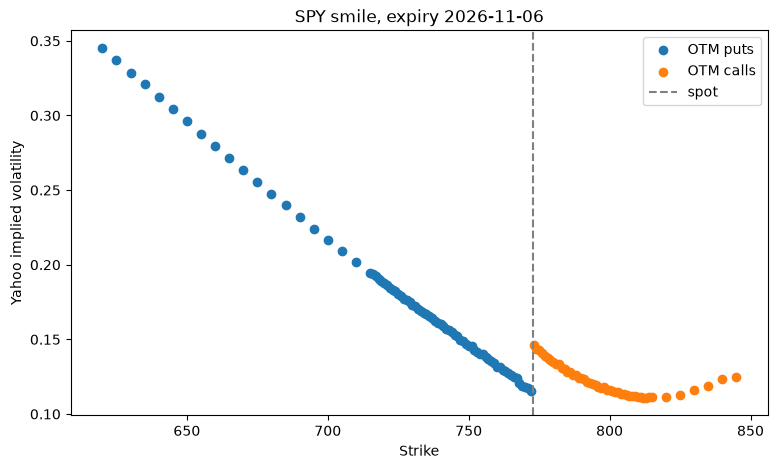

In [32]:
pick = pd.to_datetime(expiries[9])
one = options[options["expiry"] == pick]
otm_puts = one[(one["type"] == "put") & (one["moneyness"] >= 0.8) & (one["moneyness"] < 1.0)]
otm_calls = one[(one["type"] == "call") & (one["moneyness"] >= 1.0) & (one["moneyness"] <= 1.1)]

plt.figure(figsize = (9, 5))
plt.scatter(otm_puts["strike"], otm_puts["impliedVolatility"], label="OTM puts")
plt.scatter(otm_calls["strike"], otm_calls["impliedVolatility"], label="OTM calls")
plt.axvline(spot, color="grey", linestyle="--", label="spot")
plt.xlabel("Strike")
plt.ylabel("Yahoo implied volatility")
plt.title("SPY smile, expiry " + expiries[9])
plt.legend()
plt.show()

A first look at the smile for the 6 November expiry. If Black-Scholes were right, implied vol would be the same at every strike. Instead it climbs from about 12% near spot to 34.5% at K = 620, so the market charges far more for protection against a fall than the model would.

Something else looked wrong: right at spot, puts show about 11.5% and calls about 14.6%. Put-call parity says they should match, so the gap must come from Yahoo's own assumptions (rates, dividends, stale prices). That's why in notebook 2 I recompute every implied vol myself from mid prices.

Cleaning. I apply seven rules, in this order:

1. At least 7 days to expiry: with tiny T the price barely depends on vol, so the implied vol is unstable.
2. Bid above zero: with no buyer, the mid isn't a real price.
3. Ask above bid: anything else is broken data, often 0/0 after the close.
4. Spread under 50% of mid: a very wide spread means we don't really know the price.
5. Mid of at least 5 cents: prices move in 1-cent ticks, so at 2 cents one tick is a 50% change.
6. Out-of-the-money only (puts below spot, calls above): their price is pure time value, so they carry the vol information.
7. Strikes between 70% and 130% of spot: the far wings barely trade.

In [33]:
clean = options.copy()
print("Start:", len(clean))

clean = clean[clean["T"] >= 7/365]
print("After dropping expiries under 7 days:", len(clean))

clean = clean[clean["bid"] > 0]
print("After dropping zero bids:", len(clean))

clean = clean[clean["ask"] > clean["bid"]]
print("After dropping broken quotes:", len(clean))

# e.g. bid 1.00, ask 1.10 -> mid 1.05 -> spread_pct = 0.10 / 1.05 = 9.5%
clean["spread_pct"] = (clean["ask"] - clean["bid"]) / clean["mid"]
clean = clean[clean["spread_pct"] < 0.5]
print("After dropping wide spreads:", len(clean))

clean = clean[clean["mid"] >= 0.05]
print("After dropping prices under 5 cents:", len(clean))

otm_put = (clean["type"] == "put") & (clean["moneyness"] < 1)
otm_call = (clean["type"] == "call") & (clean["moneyness"] >= 1)
clean = clean[otm_put | otm_call]
print("After keeping only OTM options:", len(clean))

clean = clean[(clean["moneyness"] >= 0.7) & (clean["moneyness"] <= 1.3)]
print("After keeping moneyness 0.7 to 1.3:", len(clean))

Start: 9474
After dropping expiries under 7 days: 8424
After dropping zero bids: 7922
After dropping broken quotes: 7913
After dropping wide spreads: 7692
After dropping prices under 5 cents: 7516
After keeping only OTM options: 4318
After keeping moneyness 0.7 to 1.3: 3199


In [34]:
clean.to_csv(f"spy_options_clean_{date_str}.csv", index=False)
print("Saved spy_options_clean_" + date_str + ".csv")

Saved spy_options_clean_2026-10-08.csv


expiry
2026-10-15     78
2026-10-16    108
2026-10-23    117
2026-10-30    209
2026-11-06    141
2026-11-13    137
2026-11-20    146
2026-11-30    255
2026-12-18    174
2026-12-31    288
2027-01-15     84
2027-01-29    167
2027-02-26    140
2027-03-19     92
2027-03-31    167
2027-06-17     92
2027-06-30    168
2027-09-17     92
2027-09-30     87
2027-12-17     92
2028-01-21     92
2028-06-16     92
2028-12-15     92
2029-01-19     89
dtype: int64

In [ ]:
clean.groupby("expiry").size()  # every expiry should still have enough strikes for a smile

Out of 9,474 options downloaded, 3,199 survive the cleaning, spread over 24 expiries. Notebook 2 starts from spy_options_clean_2026-10-08.csv.